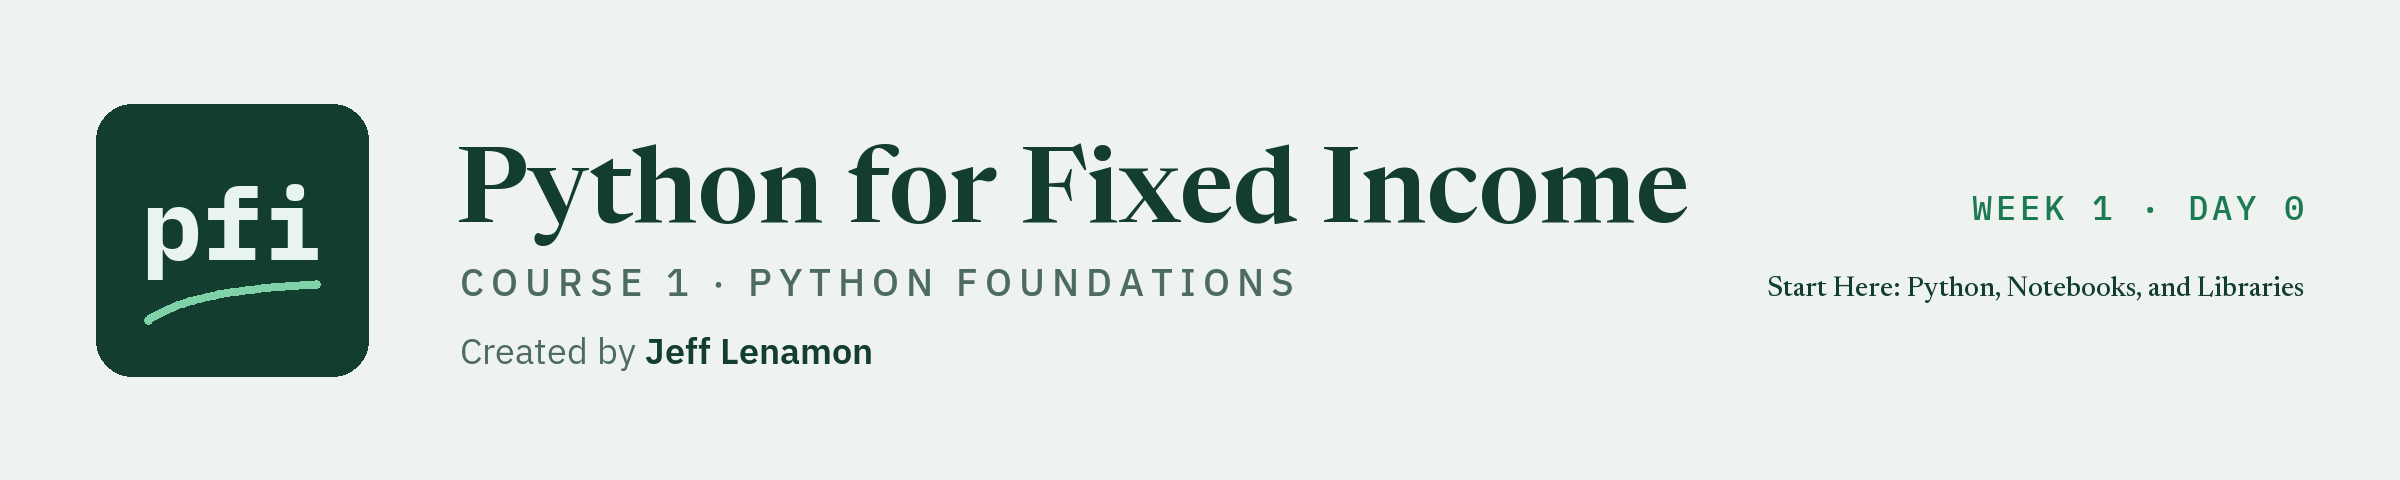

# Python for Fixed Income: Start Here

Week 1, Day 0. Ground zero: what Python is, what a notebook is, what a `.py` file is, and what a library is, for someone who has never opened a notebook.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course1_python_foundations/week1/day0/00_start_here.ipynb)

**How to run a cell.** A notebook is made of cells: text cells like this one, and code cells that hold Python. To run a code cell:

* **One cell:** click in it and press **Shift + Enter**. The cell runs, its result shows underneath, and the cursor moves to the next cell. You can also click the small play button (a triangle) at the left of the cell.
* **Every cell, top to bottom:** use **Run All**. In VS Code it is in the toolbar at the top of the notebook. In Colab it is in the **Runtime** menu (Runtime, then Run all), or press **Ctrl + F9**.

A number in square brackets appears at the left of a code cell once it has run: the order the cells ran in. Run the cells from the top, in order, unless a cell says otherwise.

## Before you start: install the libraries

Run this cell first. It checks that every library this course pins in its `requirements.txt` is installed and installs only what is missing, so it finishes in a second on a machine set up from the repo's `requirements.txt` and does the installing for you in Google Colab. If it installs anything in Colab, restart the session (Runtime, Restart session) and run the notebook again from the top.

In [1]:
# install what this notebook needs: the course's pinned libraries, only those not already present
import importlib.util
import subprocess
import sys

# import name: the pinned package, from course1_python_foundations/requirements.txt
NEEDED = {
    "ipykernel": "ipykernel==7.4.0",
    "jinja2": "jinja2==3.1.6",
    "matplotlib": "matplotlib==3.11.2",
    "nbformat": "nbformat==5.11.1",
    "nltk": "nltk==3.10.3",
    "numpy": "numpy==2.5.3",
    "openpyxl": "openpyxl==3.1.5",
    "pandas": "pandas==3.0.6",
    "plotly": "plotly==7.1.0",
    "pytest": "pytest==9.1.1",
    "seaborn": "seaborn==0.13.2",
}

# a package is present when Python can find its module; the version is left as the machine has it
missing = [pin for module, pin in NEEDED.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", *missing], check=True)
    print(f"{len(NEEDED)} packages checked, {len(missing)} installed: restart the session and run again from the top")
else:
    print(f"{len(NEEDED)} packages checked, all present")

11 packages checked, all present


## Before Anything Else

This notebook assumes nothing. If you have never written a line of code, never opened a notebook, and are not sure what the word Python means here, you are in the right place. Day 1 starts writing code on bonds. This notebook explains the tools you will be using, so that nothing on day 1 is a mystery.

You are reading a **notebook** right now. You may have opened it in VS Code on your own computer, or in Colab in your web browser. Either way it works the same.

Today you will:

1. Learn what Python is: a language, and the engine that runs it.
2. Learn what a notebook is, and its two kinds of cells: **markdown** cells for text and **code** cells for Python.
3. Learn what a `.py` file is, and how it differs from a notebook.
4. Learn what a **library** is, and why Python needs them.
5. Run your first few lines of Python.

Every section has small cells to run. Run them in order, from the top.

## 0.1 What Python Is

**Python is a programming language.** A programming language is a precise way of writing instructions for a computer. "Add up these three prices" is an instruction a person understands. Python is a way of writing the same instruction so that a computer can carry it out exactly, every time.

**Python is also a program on your computer that runs those instructions.** When people say "install Python", they mean this program. Think of it as an **engine**. It reads the instructions you write, one line after another, and carries them out. On its own it has no grid, no buttons, and no menus: it sits idle until someone hands it instructions. Everything else you will meet, the notebook, VS Code, Colab, is a place to write instructions and hand them to that engine.

Here is the difference from the tool you already know. Excel is the grid you see *and* the engine that calculates it, in one application. Python separates them. The engine is Python. Where you write is up to you, and in this course it is a notebook.

Q. Hand the engine its first instruction. Click in the code cell below and press **Shift + Enter**.

In [2]:
print("Good morning, bond desk")

Good morning, bond desk


* Python carried out the instruction: `print` means "show this on the screen", and the text inside the quotes is what to show. The result appears right under the cell.

Q. The engine is also a calculator. What is a 5.25 percent coupon split into two semiannual payments?

In [3]:
5.25 / 2

2.625

* 2.625. The `/` sign means divide, `*` multiply, `+` add, and `-` subtract, as in an Excel formula, but with no `=` in front.

Q. Which version of the engine is running this notebook? The first line below asks Python for one of its built-in tools, called `sys`; section 0.5 explains what that means.

In [4]:
import sys

# the major and minor version numbers of the Python running this notebook (the f before the quotes is explained on day 1)
print(f"Python {sys.version_info.major}.{sys.version_info.minor}")

Python 3.13


* Python 3.13, the version this course is built and tested on. Python's version matters for the same reason an Excel version can: a newer version can do things an older one cannot.

## 0.2 What a Notebook Is

**A notebook is a document that mixes text, code, and results.** It is saved as a file whose name ends in `.ipynb` (the letters stand for "IPython notebook", from the project the format came from). You open it in a notebook program: VS Code, Jupyter, or Colab.

A notebook is a column of **cells**, read from top to bottom. Behind it, while it is open, runs a copy of the Python engine called the **kernel**. When you run a code cell, the notebook hands that cell's instructions to the kernel, the kernel carries them out, and the result appears under the cell. When you save, the file keeps your text, your code, and the results, so the next person who opens it sees what you saw.

| Part | What it is |
| --- | --- |
| Cell | One box in the column. Each cell is either a code cell or a markdown cell. |
| Code cell | A box of Python instructions. Running it hands them to the kernel. |
| Markdown cell | A box of text: headings, explanations, tables, like this one. Python ignores it. |
| Output | What a code cell shows under itself after it runs. |
| Kernel | The copy of the Python engine behind the notebook. It runs the code and remembers what it has done. |
| `.ipynb` file | The saved notebook: cells, code, and outputs, together in one file. |

Think of a workbook where the notes and the formulas sit on one page, in order, and the page records what each formula gave.

## 0.3 Two Kinds of Cells: Markdown and Code

**Markdown cells hold text.** Markdown is a simple way of formatting text with a few symbols. You type the symbols, and when the cell is run (rendered) they turn into formatting:

| You type | You see |
| --- | --- |
| `# Bond desk` | a large heading |
| `## Morning check` | a smaller heading |
| `**coupon**` | **coupon** in bold |
| `* first point` at the start of a line | a bullet point |

To edit a markdown cell, double-click it and you see the symbols. Press **Shift + Enter** and it turns back into formatted text. This cell is a markdown cell. Double-click it to see how it was written, then press Shift + Enter to put it back.

**Code cells hold Python.** You type instructions, press **Shift + Enter**, and the result appears underneath. A number in square brackets appears at the left of a code cell once it has run: the order the cells ran in.

**Adding a cell.** In VS Code, the **+ Code** and **+ Markdown** buttons at the top of the notebook add a cell, and a new cell can be switched between Python and Markdown with the language name at its bottom right. In Colab the buttons are **+ Code** and **+ Text**.

Q. A code cell can store a value under a name, so a later cell can use it. Run the two cells below, in order.

In [5]:
# store the coupon, in percent, under the name coupon
coupon = 5.25

In [6]:
# a later cell can use the stored value
coupon / 2

2.625

* The first cell showed nothing: storing a value prints nothing. The second cell used the stored `coupon` and gave 2.625.
* The kernel remembers what each cell did, in the order you ran the cells, not the order they sit on the page. That is why the course says: run the cells from the top, in order. If a notebook ever gets confusing, **Restart** the kernel (it forgets everything) and **Run All** (it runs every cell again, in order). Day 1 comes back to this.

## 0.4 What a .py File Is

**A `.py` file is a plain text file that holds only Python.** No markdown cells, no saved outputs: just instructions, one line after another. You can open one in any text editor, even Notepad. When Python runs a `.py` file, it reads it from the top and carries out every line in one go, from start to end. On a computer this is usually typed in a terminal as `python` followed by the file's name.

People use `.py` files for code they keep and use again: a set of bond calculations that many notebooks share, or a job that runs every morning by itself. Notebooks are for working step by step and showing the results; `.py` files are for code you reuse. In this course you write both: later on you build your own `.py` files of functions and use them from notebooks.

Q. Write a two-line `.py` file and run it the way a terminal would. You do not need to follow every line of this cell yet: read the comments.

In [7]:
import shutil
import subprocess
import tempfile
from pathlib import Path

# a new, empty folder in the computer's temporary space, outside the course, so nothing is left behind
folder = Path(tempfile.mkdtemp())
script = folder / "half_coupon.py"

# the whole .py file: two lines of Python, saved as plain text
script.write_text('coupon = 5.25\nprint("Half the coupon:", coupon / 2)\n')
print("The file holds:")
print(script.read_text())

# run the file from start to end, as typing  python half_coupon.py  in a terminal would
result = subprocess.run([sys.executable, str(script)], capture_output=True, text=True)
print("When Python ran it, it printed:", result.stdout)

# delete the folder and the file in it
shutil.rmtree(folder)

The file holds:
coupon = 5.25
print("Half the coupon:", coupon / 2)

When Python ran it, it printed: Half the coupon: 2.625



* The file held two lines of Python and nothing else. Python ran it top to bottom and printed one line. Nothing was saved in the file afterwards: a `.py` file keeps code, not results.

| | Notebook (`.ipynb`) | Python file (`.py`) |
| --- | --- | --- |
| Holds | text, code, and results | code only |
| Runs | one cell at a time, when you choose | the whole file, top to bottom |
| Good for | working step by step, explaining, showing results | code you keep and use again |
| Opened in | VS Code, Jupyter, Colab | any editor; run by Python |

## 0.5 Libraries: Code Someone Already Wrote

Python on its own is the engine and a small set of built-in commands, such as `print`, `len` (how many), `sum`, `max`, and `min`. Almost everything else you will use comes in **libraries**: collections of code that someone has already written and tested, ready for you to use. A library for dates, a library for statistics, a library for tables of data, a library for charts.

A library is used in two steps:

1. **Install it, once.** This copies the library onto your computer. Many libraries, called the **standard library**, come with Python and are already there. Others are downloaded from **PyPI**, the Python Package Index, with a program called **pip** that comes with Python.
2. **Import it, in each notebook.** `import` makes an installed library available in the notebook you are working in. It has to be run each time the notebook starts, because the kernel starts with a clean memory.

The cell near the top of every notebook in this course, under "Before you start: install the libraries", does step 1 for you: it checks the course's list of libraries, `requirements.txt`, and installs any that are missing.

Q. First, the built-in commands. How many prices are there, and what do they add up to?

In [8]:
prices = [98.50, 101.25, 99.75]
print("Count:", len(prices))
print("Total:", sum(prices))

Count: 3
Total: 299.5


* `prices` holds three numbers in square brackets: a **list**, which day 1 covers. `len` counted them and `sum` added them, with no import: they are built in.

Q. Now a library from the standard library, `statistics`. What is the average price?

In [9]:
import statistics

# mean is a function inside the statistics library: library name, a dot, then the function
statistics.mean(prices)

99.83333333333333

* 99.833... The library came with Python, so it only had to be imported. The dot in `statistics.mean` means "the `mean` that lives inside `statistics`".

Q. Another standard library, `datetime`. How many days are there from one coupon date to the next?

In [10]:
from datetime import date

# from datetime, take only date; then subtract one date from another
days = date(2026, 7, 15) - date(2026, 1, 15)
print(days.days, "days")

181 days


* 181 days, counted on the calendar. `from datetime import date` takes one piece of a library instead of the whole thing.

Q. Now a library that does not come with Python: **pandas**, the library for tables of data that this course uses from week 2 on. The install cell at the top installed it. Import it and build a small table of three bonds.

In [11]:
# import pandas, and call it pd for short: every pandas user does the same
import pandas as pd

bonds = pd.DataFrame({"ticker": ["TRNW", "OSMC", "CLDB"], "coupon": [4.375, 5.00, 8.25], "price": [96.25, 100.00, 104.50]})
bonds

,ticker,coupon,price
0,TRNW,4.375,96.25
1,OSMC,5.000,100.00
2,CLDB,8.250,104.50


* A table, laid out like a worksheet: one row per bond, one column per field. `pd` is a nickname set by `as pd`; `pd.DataFrame` means "the DataFrame that lives in pandas", the way `statistics.mean` did.
* The issuers behind these tickers are invented. Every bond in this course is.

Q. What happens if you import a library that is not installed? The cell below is meant to fail: run it and read the last line of the message.

In [12]:
import bondtools

ModuleNotFoundError: No module named 'bondtools'

* `ModuleNotFoundError: No module named 'bondtools'`. Python looked for a library of that name and found none. There is no library called `bondtools`; the cell was written to show the message. When you meet this message for a real library, it means one of two things: the library is not installed (run the install cell at the top, or ask how to install it), or its name is spelt wrong. Names are case-sensitive: `pandas` and `Pandas` are different names.
* An error message is not a disaster. Python stops, says what went wrong, and waits. Day 3 is about reading error messages.

## 0.6 Where Your Python Runs

There are two ways to follow this course, and the notebooks are the same in both. The course's front page, `README.md`, has the steps.

* **On your own Windows computer, in VS Code.** You install Python and VS Code, then make a **virtual environment**: a folder, `.venv`, that holds one copy of Python and the libraries for this course, kept apart from anything else on the computer, so another project can never change them.
* **In Colab, in your web browser.** Python runs on Google's computers and nothing is installed on yours. Use only public or synthetic data there, such as this course's, because anything you upload leaves your machine. On a work computer, your firm's policy comes first.

## Excel Side by Side

You already know most of these ideas from Excel, under other names.

| In Excel | In Python |
| --- | --- |
| A workbook file (`.xlsx`) | A notebook file (`.ipynb`) |
| Excel, the application that calculates | Python, the engine that runs the code |
| A cell holding a formula, such as `=5.25/2` | A code cell holding `5.25 / 2` |
| A text box or a note on the sheet | A markdown cell |
| Pressing F9 to calculate the workbook | Run All |
| A function such as `SUM` or `AVERAGE` | A built-in such as `sum`, or a library function such as `statistics.mean` |
| An add-in, such as the Analysis ToolPak, switched on to add tools | A library, installed and then imported |
| A VBA module: code saved apart from the sheets | A `.py` file |

One difference matters from the first day: an Excel formula recalculates by itself when a cell it uses changes. A Python cell runs only when you run it. Day 1 shows what follows from that.

## Where the Name Comes From

Python was created by Guido van Rossum at CWI (Stichting Mathematisch Centrum) in the Netherlands. He started it during the 1989 Christmas holidays, and in February 1991, after just over a year of work, he posted it to USENET, an early internet discussion system. The name has nothing to do with snakes: when he began, he was reading the scripts of *Monty Python's Flying Circus*, the BBC comedy series from the 1970s, and wanted a name that was short, unique, and slightly mysterious.

Sources: the Python documentation's FAQ, "Why was Python created in the first place?" and "Why is it called Python?" (https://docs.python.org/3/faq/general.html), and its "History of the software" (https://docs.python.org/3/license.html), read 25 October 2026.

## You Can Now

* Say what Python is: a language for instructions, and the engine on your computer that runs them.
* Say what a notebook is, and tell a markdown cell from a code cell.
* Run a cell with Shift + Enter, and run a whole notebook with Run All.
* Say what a `.py` file is and when people use one instead of a notebook.
* Say what a library is, import one, and read the error when one is missing.

Next, day 1: Introduction to Python, on four bonds.

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`. Give each exercise a real try first, then check your work against it.

Replace each `...` with your own code, then run the check cell under it.

Run the next cell first. It defines `check`, a small function that marks your answers.

In [13]:
def check(label, answer, expected):
    """Compare an exercise answer to the expected value and print the result."""
    if answer is ... or answer is None:
        print(label + ': not attempted yet')
    elif answer == expected:
        print(label + ': correct')
    else:
        print(label + ': not yet. You have', answer)

### Exercise 1

Q. A position holds 1,000,000 face of a bond with a 4.5 percent coupon. What is the annual coupon income? (Face times coupon, divided by 100.) Store it in **ex1_income**.

In [14]:
ex1_income = ...

In [15]:
check('Exercise 1', ex1_income, 45000.0)

Exercise 1: not attempted yet


### Exercise 2

Q. Three prices: 99.50, 100.25, and 101.00. Use the `statistics` library to find their average, and store it in **ex2_average**.

In [16]:
ex2_average = ...

In [17]:
check('Exercise 2', ex2_average, 100.25)

Exercise 2: not attempted yet


### Exercise 3

Q. Use `date` from the `datetime` library to count the days from 15 January 2026 to 15 July 2026, and store the number in **ex3_days**.

In [18]:
ex3_days = ...

In [19]:
check('Exercise 3', ex3_days, 181)

Exercise 3: not attempted yet


### Exercise 4

Q. Add a markdown cell below this one. Give it a heading that says `My bond desk` and two bullet points: one naming a bond you know, one saying what you want to learn in this course. Run it with Shift + Enter so it shows as formatted text. There is no check: the worked notebook shows one way to write it.

### Exercise 5: AI check

You ask an AI assistant for code that builds a table of the three bonds with pandas. It gives you the code below. It was written for this course in the style of an AI answer, and it has one bug.

Q. Read the code before you run it. Then run it, and read the last line of the message.

In [20]:
# written for this course in the style of an AI assistant's answer. It contains one bug.
import Pandas as pd

bonds = pd.DataFrame({"ticker": ["TRNW", "OSMC", "CLDB"], "price": [96.25, 100.00, 104.50]})
print(bonds)

ModuleNotFoundError: No module named 'Pandas'

Q. Find the bug, fix it in a new cell, and store the number of rows of the fixed table in **ex5_rows**. (`len(bonds)` counts the rows.)

In [21]:
ex5_rows = ...

In [22]:
check('Exercise 5', ex5_rows, 3)

Exercise 5: not attempted yet
